# Лабораторна робота №5
## Вступ до TensorFlow і побудова простої нейронної мережі для регресії

**Студент:** Гальченко Ян  
**Варіант:** 8  

**Мета:** навчитися працювати з тензорами TensorFlow, побудувати та навчити нейронну мережу для регресії, оцінити її на незалежних даних, проаналізувати історію навчання й зберегти модель у форматі `.keras`.

**Індивідуальне завдання (Варіант 8):** порівняти базову модель із моделлю варіанта 8, де в прихованих шарах використано `Dense(64, activation="relu")` та задано `batch_size=16`.

TensorFlow — бібліотека для створення й навчання нейронних мереж. NumPy потрібний для числових даних, Matplotlib — для графіків навчання.

In [26]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.22.0-rc0
NumPy: 2.5.3


Підключаємо всі бібліотеки, потрібні для роботи. Вивід версій підтверджує, що TensorFlow успішно встановився, і його версію треба зазначити у звіті.

## Перевірка середовища

Підключено бібліотеки NumPy, TensorFlow і Matplotlib. Версії бібліотек виведено для фіксації середовища виконання та відтворюваності результатів. 

In [27]:
a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.])

w = tf.Variable([0.2, 0.5])
w.assign([0.3, 0.6])

print("shape a:", a.shape)
print("dtype a:", a.dtype)
print("rank a:", tf.rank(a).numpy())

print("\na + b:")
print(a + b)

print("\na * a:")
print(a * a)

print("\ntf.matmul(a, a):")
print(tf.matmul(a, a))

print("\nw після assign:")
print(w.numpy())

shape a: (2, 2)
dtype a: <dtype: 'float32'>
rank a: 2

a + b:
tf.Tensor(
[[11. 22.]
 [13. 24.]], shape=(2, 2), dtype=float32)

a * a:
tf.Tensor(
[[ 1.  4.]
 [ 9. 16.]], shape=(2, 2), dtype=float32)

tf.matmul(a, a):
tf.Tensor(
[[ 7. 10.]
 [15. 22.]], shape=(2, 2), dtype=float32)

w після assign:
[0.3 0.6]


Коментар: `tf.constant` створює незмінний тензор, а `tf.Variable` — змінний, значення якого можна оновлювати під час навчання моделі. `shape` показує розміри тензора, `dtype` — тип даних, а `rank` — кількість осей. Додавання `a + b` працює через broadcasting: вектор `b` застосовується до кожного рядка матриці `a`. Вираз `a * a` множить елементи на відповідні елементи, а `tf.matmul(a, a)` виконує матричне множення.

## Робота з тензорами

Створено незмінні тензори `tf.constant` і змінну `tf.Variable`. Тензор `a` має ранг 2, форму `(2, 2)` та тип `float32`. Операція `a + b` можлива завдяки broadcasting: вектор `b` додається до кожного рядка матриці `a`. Поелементне множення `a * a` відрізняється від `tf.matmul(a, a)`, оскільки другий вираз виконує матричне множення.

In [28]:
SEED = 42

keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)

y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

x = x.reshape(-1, 1)
y = y.reshape(-1, 1)

idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Тип даних x:", x.dtype)

Train: (420, 1) (420, 1)
Validation: (90, 1) (90, 1)
Test: (90, 1) (90, 1)
Тип даних x: float32


Коментар: створюємо 600 штучних прикладів, де між `x` та `y` є нелінійний зв’язок через `sin(2*x)` і випадковий шум. Потім перемішуємо дані та ділимо їх: 420 прикладів (70%) для навчання, 90 (15%) для validation і 90 (15%) для фінального test. Validation використовується для вибору кращої моделі, а test не можна використовувати для підбору гіперпараметрів.

Коментар: створюємо 600 штучних прикладів, де між `x` та `y` є нелінійний зв’язок через `sin(2*x)` і випадковий шум. Потім перемішуємо дані та ділимо їх: 420 прикладів (70%) для навчання, 90 (15%) для validation і 90 (15%) для фінального test. Validation використовується для вибору кращої моделі, а test не можна використовувати для підбору гіперпараметрів.

In [29]:
def build_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

model = build_model()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

model.summary()

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=16,  # Параметр batch_size=16
    verbose=0
)

print("Найменший val_loss (Baseline):", min(history.history["val_loss"]))

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

Найменший val_loss (Baseline): 0.6081773042678833


Коментар: базова модель має один вхід, два приховані шари по 16 нейронів із функцією активації `relu` та вихідний шар `Dense(1)` без активації, бо прогнозуємо числове значення. `compile()` задає алгоритм Adam, функцію втрат MSE і метрику MAE. `fit()` навчає модель на train та після кожної епохи перевіряє її на validation із розміром пакета `batch_size=16`.

## Базова нейронна мережа

Побудовано базову модель `Sequential` з двома прихованими шарами `Dense(16, relu)` і вихідним шаром `Dense(1)`. Модель навчається оптимізатором Adam з learning rate 0.01, функцією втрат MSE та метрикою MAE при `batch_size=16`. Валідаційна вибірка використовується для контролю навчання й вибору кращого варіанта моделі.

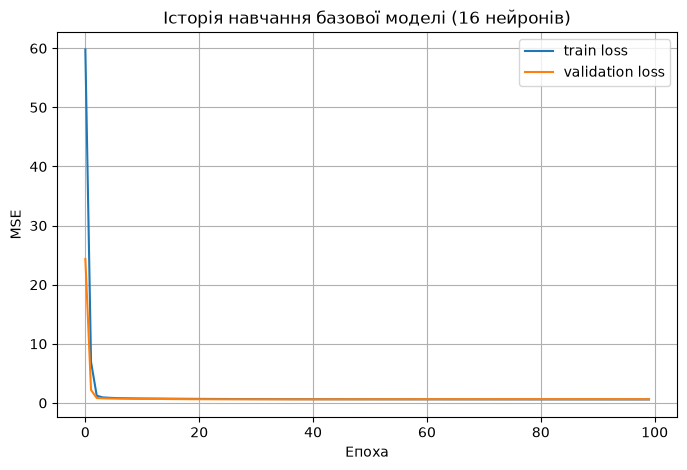

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")

plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Історія навчання базової моделі (16 нейронів)")
plt.legend()
plt.grid(True)

plt.show()

Коментар: `loss` показує помилку моделі на навчальній вибірці, а `val_loss` — на незалежній валідаційній. За цими кривими оцінюємо, як модель навчається. Якщо train loss зменшується, а val_loss починає зростати, це свідчить про перенавчання.

### Аналіз навчання базової моделі

Побудовано графік `loss` і `val_loss` за 100 епох. Криві показують зміну MSE на навчальній та валідаційній вибірках. Найменше значення `val_loss` використовується для порівняння базової моделі з моделлю індивідуального варіанта.

In [31]:
keras.utils.set_random_seed(SEED)

def build_var8_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)
    ])

model_var8 = build_var8_model()

model_var8.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

history_var8 = model_var8.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=16,  # Параметр batch_size=16
    verbose=0
)

print("Найменший val_loss baseline (16 units):", min(history.history["val_loss"]))
print("Найменший val_loss variant 8 (64 units):", min(history_var8.history["val_loss"]))

Найменший val_loss baseline (16 units): 0.6081773042678833
Найменший val_loss variant 8 (64 units): 0.7462995648384094


Коментар: у варіанті 8 змінюємо кількість нейронів у прихованих шарах з 16 до 64, залишаючи функцію активації `relu` та параметр `batch_size=16`. Збільшення ємності моделі дозволяє краще апроксимувати складну нелінійну залежність даних. `keras.utils.set_random_seed(SEED)` робить порівняння чесним завдяки однаковій ініціалізації ваг.

## Індивідуальний варіант 8

Створено другу модель зі збільшеною кількістю нейронів у прихованих шарах до 64 (`Dense(64, relu)`). Інші налаштування — оптимізатор, learning rate, кількість епох і `batch_size=16` — залишено без змін. Моделі порівнюються за найменшим `val_loss`.

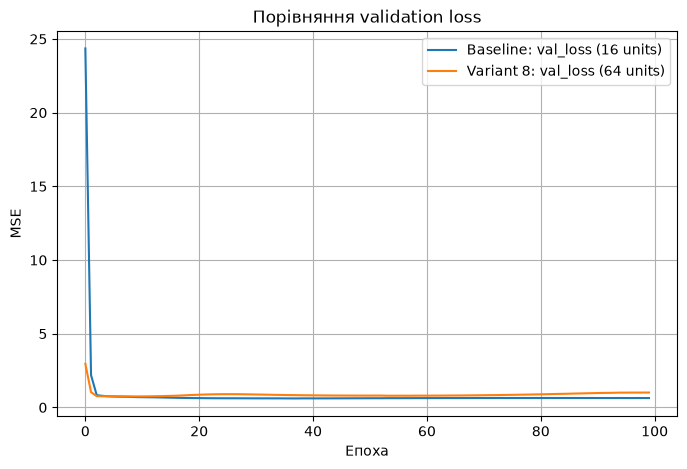

Найменший val_loss baseline: 0.6081773042678833
Найменший val_loss variant 8: 0.7462995648384094


In [32]:
baseline_min_val_loss = min(history.history["val_loss"])
var8_min_val_loss = min(history_var8.history["val_loss"])

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["val_loss"],
    label="Baseline: val_loss (16 units)"
)

plt.plot(
    history_var8.history["val_loss"],
    label="Variant 8: val_loss (64 units)"
)

plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Порівняння validation loss")
plt.legend()
plt.grid(True)

plt.show()

print("Найменший val_loss baseline:", baseline_min_val_loss)
print("Найменший val_loss variant 8:", var8_min_val_loss)

Коментар: порівнюємо моделі саме за `val_loss`, бо validation-набір не брав участі у навчанні. Кращим кандидатом є модель з меншим значенням `val_loss`.

### Порівняння моделей за validation

Для baseline-моделі та моделі з 64 нейронами побудовано графік валідаційної MSE. Кращою за validation вважається модель із меншим мінімальним значенням `val_loss`. Test-вибірка на цьому етапі не використовується, оскільки вона призначена лише для фінальної незалежної оцінки.

In [33]:
if var8_min_val_loss < baseline_min_val_loss:
    best_model = model_var8
    best_model_name = "Variant 8 model (64 units)"
else:
    best_model = model
    best_model_name = "Baseline model (16 units)"

baseline_eval = model.evaluate(x_test, y_test, verbose=0)
var8_eval = model_var8.evaluate(x_test, y_test, verbose=0)

comparison = pd.DataFrame(
    [
        {
            "Модель": "Baseline (16 units)",
            "Мінімальний val_loss": baseline_min_val_loss,
            "Test MSE": baseline_eval[0],
            "Test MAE": baseline_eval[1]
        },
        {
            "Модель": "Варіант 8 (64 units)",
            "Мінімальний val_loss": var8_min_val_loss,
            "Test MSE": var8_eval[0],
            "Test MAE": var8_eval[1]
        }
    ]
)

display(comparison.round(4))
print("Краща модель за validation:", best_model_name)

,Модель,Мінімальний val_loss,Test MSE,Test MAE
0,Baseline (16 units),0.6082,0.5831,0.5960
1,Варіант 8 (64 units),0.7463,0.8260,0.7082


Краща модель за validation: Baseline model (16 units)


Коментар: модель обирається за найменшим `val_loss`, а не за test-метриками. Після вибору test застосовується для фінальної незалежної оцінки. У таблиці є всі обов’язкові результати: мінімальний `val_loss`, test MSE і test MAE для baseline та варіанта 8.

    ## Порівняння baseline і варіанта 8

Моделі порівняно за мінімальним значенням `val_loss`, test MSE та test MAE. Вибір кращої моделі зроблено за validation, а test-вибірку використано для фінальної оцінки.

In [34]:
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)

y_new_pred = best_model.predict(x_new, verbose=0)

predictions_table = pd.DataFrame({
    "x": x_new.flatten(),
    "Прогноз y": y_new_pred.flatten()
})

display(predictions_table.round(3))

,x,Прогноз y
0,-4.0,-10.546
1,0.0,1.946
2,4.0,14.575


Коментар: створюємо три нові значення входу `x = -4`, `0` і `4`. Краща за validation модель обчислює для них числові прогнози `y`. Це демонструє застосування `predict()` до нових даних, яких не було у навчальній вибірці.

## Прогнозування нових значень

Для трьох нових значень `x = -4`, `0` і `4` отримано прогнози кращої моделі. Метод `predict()` повертає числові значення цільової змінної.

In [35]:
model_path = "lab5_model.keras"

best_model.save(model_path)

restored = keras.models.load_model(model_path)

np.testing.assert_allclose(
    best_model.predict(x_new, verbose=0),
    restored.predict(x_new, verbose=0),
    rtol=1e-5
)

print(f"Модель збережено у файлі: {model_path}")
print("Перевірку пройдено: прогнози до і після завантаження збігаються.")

Модель збережено у файлі: lab5_model.keras
Перевірку пройдено: прогнози до і після завантаження збігаються.


Коментар: `.keras` зберігає архітектуру моделі, її ваги та налаштування. Потім модель завантажується у змінну `restored`. `assert_allclose` перевіряє, що її прогнози практично збігаються з прогнозами оригінальної моделі.

## Збереження та перевірка моделі

Кращу за validation модель збережено у форматі `.keras`, після чого її завантажено повторно. Збіг прогнозів оригінальної та завантаженої моделей перевірено з допустимою похибкою обчислень.

## Висновок

У роботі було опрацьовано основи TensorFlow: створення тензорів, визначення їхньої форми, рангу та типу даних, а також broadcasting і матричні операції. Для даних нелінійної регресії побудовано базову нейронну мережу та модель індивідуального варіанта 8 зі збільшеною кількістю нейронів (64) і `batch_size=16`. Моделі порівняно за мінімальним `val_loss`, test MSE і test MAE, причому вибір кращої моделі виконано за validation-вибіркою. Для кращої моделі отримано прогнози нових значень, її збережено у форматі `.keras` і успішно завантажено повторно.